# Modelo: ¿necesitará asistencia sanitaria una persona implicada en un accidente?

Accidentes de tráfico en Madrid, 2020. El modelo estima, para cada persona implicada, si necesitará asistencia
sanitaria, a partir de la hora, su edad, el distrito, el tipo de accidente, el tiempo y el vehículo.

**Qué significa cada código de lesividad.** Según la estructura oficial de los datos del Ayuntamiento de Madrid
(*Estructura DS Accidentes tráfico desde 2019*):
- 1, 2, 5, 6 y 7: asistencia sanitaria con lesión leve;
- 3: ingreso de más de 24 horas, grave;
- 4: fallecido en 24 horas;
- 14: sin asistencia sanitaria;
- 77: se desconoce; en blanco: sin dato.

El modelo compara a quien necesitó asistencia (códigos 1 a 7) con quien no la necesitó (código 14). Los graves y
fallecidos son pocos (399 de 28.773) para un modelo propio. Las filas sin código y las de código 77 quedan fuera.

Las cifras de este cuaderno las imprime cada celda al ejecutarse.


In [1]:
# ============================================
# 1️⃣ IMPORTACIÓN DE LIBRERÍAS
# ============================================
import pandas as pd          # Manejo de datos tabulares
import numpy as np           # Cálculos numéricos
import matplotlib.pyplot as plt # Gráficos
import seaborn as sns        # Visualización estadística

# Machine Learning
from sklearn.model_selection import train_test_split  # Dividir datos en entrenamiento/prueba
from sklearn.ensemble import RandomForestClassifier   # Algoritmo predictivo
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score # Métricas
from sklearn.preprocessing import LabelEncoder        # Convertir texto a números
import joblib                 # Guardar modelo entrenado
import os                     # Manejo de rutas
import warnings               # Ocultar avisos técnicos

plt.style.use('seaborn-v0_8')
print("✅ Librerías cargadas. Listo para procesar datos.")

✅ Librerías cargadas. Listo para procesar datos.


In [2]:
# ============================================
# 2️⃣ CARGA Y PREPARACIÓN DE DATOS
# ============================================
base_path = os.path.join('..', 'data', 'processed')
accidents = pd.read_csv(os.path.join(base_path, 'accidents.csv'))
involved = pd.read_csv(os.path.join(base_path, 'involved_parties.csv'))

#  Unir víctimas con contexto del accidente (clave: id_accident)
df = involved.merge(
    accidents[['id_accident', 'hora', 'distrito', 'tipo_accidente', 'estado_meteorologico']], 
    on='id_accident', how='left'
)

# 🎯 Objetivo: 1 = necesitó asistencia sanitaria (códigos 1 a 7), 0 = sin asistencia (código 14).
# Fuera: sin código y 77 (se desconoce). Códigos según la estructura oficial del Ayuntamiento.
df['target'] = df['lesividad'].apply(lambda x: 1 if pd.notna(x) and 1 <= x <= 7 else (0 if x == 14 else np.nan))
df = df.dropna(subset=['target'])
df['target'] = df['target'].astype(int)

# 🔢 CONVERSIÓN DE EDAD: De texto ("DE 25 A 29 AÑOS") a número (27)
import re
def rango_a_numero(texto):
    if pd.isna(texto): return np.nan
    # Casos especiales
    if "MENOR" in str(texto).upper(): return 15
    if "MAYOR" in str(texto).upper(): return 68
    # Extraer los dos números del rango y calcular el punto medio
    nums = re.findall(r'\d+', str(texto))
    if len(nums) >= 2:
        return (int(nums[0]) + int(nums[1])) / 2
    return np.nan

df['edad_num'] = df['edad'].apply(rango_a_numero)

# 🧹 LIMPIEZA FINAL: Rellenar vacíos con la mediana (valor más representativo)
df['hora'] = df['hora'].fillna(df['hora'].median())
df['edad_num'] = df['edad_num'].fillna(df['edad_num'].median())
df['distrito'] = df['distrito'].fillna('Desconocido')
df['tipo_accidente'] = df['tipo_accidente'].fillna('Desconocido')
df['estado_meteorologico'] = df['estado_meteorologico'].fillna('Desconocido')
df['tipo_vehiculo'] = df['tipo_vehiculo'].fillna('Desconocido')

print(f"✅ Dataset preparado: {len(df):,} registros válidos")
print(f"Distribución de clases:\n{df['target'].map({0: 'Sin asistencia', 1: 'Con asistencia'}).value_counts()}")

✅ Dataset preparado: 15,715 registros válidos
Distribución de clases:
target
Sin asistencia    8315
Con asistencia    7400
Name: count, dtype: int64


In [3]:
# ============================================
# 3️⃣ CODIFICACIÓN Y DIVISIÓN TRAIN/TEST
# ============================================

# 📌 Definimos las variables que usará el modelo para predecir
# Usamos 'edad_num' (ya convertida a número) en lugar de la columna original de texto
features = ['hora', 'edad_num', 'distrito', 'tipo_accidente', 'estado_meteorologico', 'tipo_vehiculo']
X = df[features].copy()
y = df['target']

# 🔄 CODIFICAR VARIABLES CATEGÓRICAS
# Los algoritmos de Machine Learning solo trabajan con números.
# LabelEncoder convierte cada categoría única a un entero (ej: "CENTRO"→2, "SALAMANCA"→5)
cat_cols = ['distrito', 'tipo_accidente', 'estado_meteorologico', 'tipo_vehiculo']
encoders = {}  # se guardan para codificar igual los casos de prueba del final
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

# 📊 DIVIDIR DATOS: 80% para entrenar, 20% para evaluar rendimiento real
# stratify=y mantiene la misma proporción de las dos clases en ambos grupos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"✅ Datos listos para el modelo:")
print(f"   📈 Entrenamiento: {len(X_train)} registros")
print(f"   🧪 Prueba (datos nunca vistos): {len(X_test)} registros")

✅ Datos listos para el modelo:
   📈 Entrenamiento: 12572 registros
   🧪 Prueba (datos nunca vistos): 3143 registros


In [4]:
# ============================================
# 4️⃣ ENTRENAMIENTO DEL MODELO PREDICTIVO
# ============================================

# 🌳 Random Forest: Algoritmo robusto que combina múltiples árboles de decisión
# - n_estimators=100: Creamos 100 árboles y promediamos sus predicciones
# - random_state=42: Semilla fija para reproducibilidad (siempre da mismos resultados)
# - class_weight='balanced': compensa que una clase tenga más casos que la otra
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

print("⏳ Entrenando modelo predictivo...")
print("   (Esto puede tardar 10-20 segundos)")

# 🎓 El modelo "aprende" patrones de los datos de entrenamiento
model.fit(X_train, y_train)

print("✅ Modelo entrenado exitosamente")
print(f"   📊 Número de árboles creados: {model.n_estimators}")
print(f"   🎯 Características utilizadas: {len(features)}")

⏳ Entrenando modelo predictivo...
   (Esto puede tardar 10-20 segundos)


✅ Modelo entrenado exitosamente
   📊 Número de árboles creados: 100
   🎯 Características utilizadas: 6


In [5]:
# ============================================
# 5️⃣ EVALUACIÓN DEL RENDIMIENTO
# ============================================

# 🔮 Predecir sobre datos NUNCA VISTOS (test)
# Esto simula cómo se comportaría el modelo con accidentes futuros
y_pred = model.predict(X_test)

print("="*60)
print("📊 REPORTE DE EVALUACIÓN DEL MODELO")
print("="*60)

# 📈 Accuracy: Porcentaje total de aciertos
accuracy = accuracy_score(y_test, y_pred)
print(f"\n🎯 Precisión Global (Accuracy): {accuracy:.2%}")
print(f"   → De cada 100 predicciones, acierta {int(accuracy*100)}")
print(f"   Referencia: decir siempre la clase más frecuente acierta {y_test.value_counts(normalize=True).max():.2%}")

# 📋 Matriz de Confusión: Detalle de aciertos/errores por clase
print("\n🔢 Matriz de Confusión:")
print("   (Filas = Valores Reales | Columnas = Predicciones)")
cm = confusion_matrix(y_test, y_pred)
print(cm)
print(f"\nInterpretación:")
print(f"  • Sin asistencia, acertados: {cm[0,0]}")
print(f"  • Sin asistencia, predichos con asistencia: {cm[0,1]}")
print(f"  • Con asistencia, predichos sin asistencia: {cm[1,0]}")
print(f"  • Con asistencia, acertados: {cm[1,1]}")

# 📝 Reporte detallado: Precisión, Recall y F1-Score por clase
print("\n📝 Reporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, target_names=['Sin asistencia (0)', 'Con asistencia (1)']))

📊 REPORTE DE EVALUACIÓN DEL MODELO

🎯 Precisión Global (Accuracy): 71.05%
   → De cada 100 predicciones, acierta 71
   Referencia: decir siempre la clase más frecuente acierta 52.91%

🔢 Matriz de Confusión:
   (Filas = Valores Reales | Columnas = Predicciones)
[[1231  432]
 [ 478 1002]]

Interpretación:
  • Sin asistencia, acertados: 1231
  • Sin asistencia, predichos con asistencia: 432
  • Con asistencia, predichos sin asistencia: 478
  • Con asistencia, acertados: 1002

📝 Reporte de Clasificación Detallado:
                    precision    recall  f1-score   support

Sin asistencia (0)       0.72      0.74      0.73      1663
Con asistencia (1)       0.70      0.68      0.69      1480

          accuracy                           0.71      3143
         macro avg       0.71      0.71      0.71      3143
      weighted avg       0.71      0.71      0.71      3143



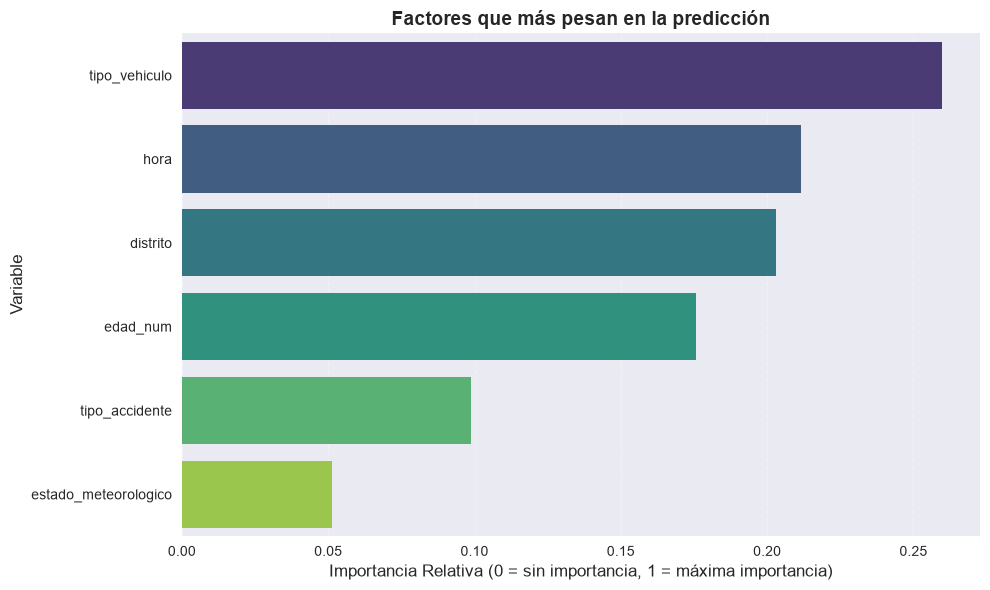


💡 INSIGHTS CLAVE:
   • La variable MÁS importante es: 'tipo_vehiculo' (26.0%)
   • La variable MENOS importante es: 'estado_meteorologico' (5.1%)

   → Esto significa que el modelo se basa principalmente en 'tipo_vehiculo' para predecir si hará falta asistencia.


In [6]:
# ============================================
# 6️⃣ INTERPRETABILIDAD: ¿QUÉ FACTORES SON MÁS IMPORTANTES?
# ============================================

# 🧠 Random Forest nos dice qué variables usó más para tomar decisiones
importances = model.feature_importances_
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)

# 📊 Crear gráfico de barras horizontal
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='viridis', legend=False)
plt.title('Factores que más pesan en la predicción', fontsize=14, fontweight='bold')
plt.xlabel('Importancia Relativa (0 = sin importancia, 1 = máxima importancia)', fontsize=12)
plt.ylabel('Variable', fontsize=12)
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# 💡 Imprimir interpretación
print("\n💡 INSIGHTS CLAVE:")
print(f"   • La variable MÁS importante es: '{feat_imp.index[0]}' ({feat_imp.values[0]:.1%})")
print(f"   • La variable MENOS importante es: '{feat_imp.index[-1]}' ({feat_imp.values[-1]:.1%})")
print(f"\n   → Esto significa que el modelo se basa principalmente en '{feat_imp.index[0]}' para predecir si hará falta asistencia.")

In [7]:
# ============================================
# 7️⃣ GUARDAR MODELO PARA USO FUTURO
# ============================================

# 📁 Crear carpeta 'models' si no existe
os.makedirs(os.path.join('..', 'models'), exist_ok=True)
model_path = os.path.join('..', 'models', 'gravedad_predictor.pkl')

# 💾 Guardar el modelo entrenado en disco (formato .pkl)
joblib.dump(model, model_path)

print("="*60)
print("✅ MODELO GUARDADO EXITOSAMENTE")
print("="*60)
print(f"\n📂 Ubicación: {model_path}")


✅ MODELO GUARDADO EXITOSAMENTE

📂 Ubicación: ..\models\gravedad_predictor.pkl


## Tres casos de prueba

Tres personas inventadas, con valores que existen en los datos. Se codifican con los mismos codificadores del
entrenamiento.


In [8]:
# ============================================
# 8️⃣ CASOS DE PRUEBA
# ============================================
def predecir(hora, edad, distrito, tipo_acc, clima, tipo_veh):
    fila = pd.DataFrame({'hora': [hora], 'edad_num': [edad], 'distrito': [distrito],
                         'tipo_accidente': [tipo_acc], 'estado_meteorologico': [clima],
                         'tipo_vehiculo': [tipo_veh]})
    for col in cat_cols:
        fila[col] = encoders[col].transform(fila[col].astype(str))
    return model.predict_proba(fila[features])[0]

escenarios = [
    ("Mañana laboral, adulto, colisión, turismo", 9, 37, 'CENTRO', 'Colisión fronto-lateral', 'Despejado', 'Turismo'),
    ("Madrugada, joven, atropello con lluvia", 3, 22, 'SALAMANCA', 'Atropello a persona', 'Lluvia débil', 'Turismo'),
    ("Tarde, mayor, caída en bicicleta", 18, 62, 'CHAMARTÍN', 'Caída', 'Despejado', 'Bicicleta'),
]
for nombre, hora, edad, distrito, tipo_acc, clima, veh in escenarios:
    prob = predecir(hora, edad, distrito, tipo_acc, clima, veh)
    print(f"{nombre}: probabilidad de necesitar asistencia {prob[1]:.0%}")


Mañana laboral, adulto, colisión, turismo: probabilidad de necesitar asistencia 14%
Madrugada, joven, atropello con lluvia: probabilidad de necesitar asistencia 47%
Tarde, mayor, caída en bicicleta: probabilidad de necesitar asistencia 96%
